<a href="https://colab.research.google.com/github/efitznm/Data-Science-Portfolio-C22/blob/main/Modules/Module_1_Intro_to_DS_and_Naive_Bayes/Projects/Instructions/Project.1-Transactions/Project.1-Pass-08.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Project.1_Pass-08, Transaction Data




## Problem Definition


State the business problem. Translate the business problem into a Data Science problem by stating what kind of problem it is ( supervised vs unsupervised ) and whether it is a classification, regression, or clustering problem.

### Business Problem
We want to predict whether or not a future customer will make a transaction based on their transaction data. The goal might be to increase customer transactions by sending targeted ads/deals to customers who are not likely to make a transaction on a given day.

### Data Science Problem
Supervised binary classification problem.

## Data Collection/Sources


### Load Pandas, Numpy, and Matplotlib modules

In [3]:
# Load Pandas, Numpy, and Matplotlib modules
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn import datasets, metrics, model_selection
from sklearn import model_selection
from sklearn.naive_bayes import GaussianNB
from sklearn.model_selection import train_test_split

### Load data Train.csv from AWS S3[link text](https://)

In [4]:
# Load the big dataset Train.big.csv from AWS S3
url = 'https://ddc-datascience.s3.amazonaws.com/Projects/Project.1-Transactions/Data/Transaction.train.big.csv'
url

df = pd.read_csv(
    url,
    usecols=range(50),
    nrows=50_000,
)

df

,Unnamed: 0,ID_code,target,var_0,var_1,var_2,var_3,var_4,var_5,var_6,...,var_37,var_38,var_39,var_40,var_41,var_42,var_43,var_44,var_45,var_46
0,0,train_0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1,train_1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2,train_2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,3,train_3,0.0,4.6739,22.3915,15.6015,NaN,0.0464,NaN,NaN,...,3.4635,17.2850,16.5520,NaN,-6.8709,NaN,NaN,NaN,NaN,NaN
4,4,train_4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49995,49995,train_49995,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
49996,49996,train_49996,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
49997,49997,train_49997,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
49998,49998,train_49998,0.0,7.7807,11.4038,11.2746,NaN,7.6426,NaN,NaN,...,5.0832,18.0498,19.0913,NaN,-0.0056,NaN,NaN,NaN,NaN,NaN


In [5]:
# Look at the first few rows
df.head()

,Unnamed: 0,ID_code,target,var_0,var_1,var_2,var_3,var_4,var_5,var_6,...,var_37,var_38,var_39,var_40,var_41,var_42,var_43,var_44,var_45,var_46
0,0,train_0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1,train_1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2,train_2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,3,train_3,0.0,4.6739,22.3915,15.6015,NaN,0.0464,NaN,NaN,...,3.4635,17.285,16.552,NaN,-6.8709,NaN,NaN,NaN,NaN,NaN
4,4,train_4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [6]:
# Look at the last few rows
df.tail()

,Unnamed: 0,ID_code,target,var_0,var_1,var_2,var_3,var_4,var_5,var_6,...,var_37,var_38,var_39,var_40,var_41,var_42,var_43,var_44,var_45,var_46
49995,49995,train_49995,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
49996,49996,train_49996,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
49997,49997,train_49997,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
49998,49998,train_49998,0.0,7.7807,11.4038,11.2746,NaN,7.6426,NaN,NaN,...,5.0832,18.0498,19.0913,NaN,-0.0056,NaN,NaN,NaN,NaN,NaN
49999,49999,train_49999,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## Data Cleaning


### Summary Meta-Data

In [7]:
# Shape of the dataframe
df.shape

(50000, 50)

In [8]:
# Size of the dataframe
df.size

2500000

In [9]:
# Display meta-data
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 50 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Unnamed: 0  50000 non-null  int64  
 1   ID_code     50000 non-null  object 
 2   target      8506 non-null   float64
 3   var_0       8506 non-null   float64
 4   var_1       8506 non-null   float64
 5   var_2       8506 non-null   float64
 6   var_3       0 non-null      float64
 7   var_4       8506 non-null   float64
 8   var_5       0 non-null      float64
 9   var_6       0 non-null      float64
 10  var_7       8506 non-null   float64
 11  var_8       8506 non-null   float64
 12  var_9       0 non-null      float64
 13  var_10      0 non-null      float64
 14  var_11      0 non-null      float64
 15  var_12      0 non-null      float64
 16  var_13      0 non-null      float64
 17  var_14      8506 non-null   float64
 18  var_15      8506 non-null   float64
 19  var_16      0 non-null   

### Summary Statistics

In [10]:
# Display summary statistics
df.describe()

,Unnamed: 0,target,var_0,var_1,var_2,var_3,var_4,var_5,var_6,var_7,...,var_37,var_38,var_39,var_40,var_41,var_42,var_43,var_44,var_45,var_46
count,50000.000000,8506.000000,8506.000000,8506.000000,8506.000000,0.0,8506.000000,0.0,0.0,8506.000000,...,8506.000000,8506.000000,8506.000000,0.0,8506.000000,0.0,0.0,0.0,0.0,0.0
mean,24999.500000,0.098754,7.433406,15.873152,12.743673,NaN,-0.666477,NaN,NaN,1.216609,...,3.335911,19.317877,18.439225,NaN,5.768740,NaN,NaN,NaN,NaN,NaN
std,14433.901067,0.298349,2.998493,3.026206,4.167618,NaN,5.989788,NaN,NaN,5.206295,...,4.541526,5.013834,4.398037,NaN,7.462482,NaN,NaN,NaN,NaN,NaN
min,0.000000,0.000000,-0.482300,7.193400,1.263600,NaN,-20.962200,NaN,NaN,-12.739600,...,-13.999500,5.133100,6.673300,NaN,-15.121100,NaN,NaN,NaN,NaN,NaN
25%,12499.750000,0.000000,5.192575,13.822750,9.709300,NaN,-4.915275,NaN,NaN,-2.600700,...,0.018500,15.712475,15.044250,NaN,0.638225,NaN,NaN,NaN,NaN,NaN
50%,24999.500000,0.000000,7.286950,15.971650,12.660600,NaN,-0.585350,NaN,NaN,1.209900,...,3.366600,19.318800,18.293700,NaN,5.958900,NaN,NaN,NaN,NaN,NaN
75%,37499.250000,0.000000,9.523925,18.092725,15.755275,NaN,3.615725,NaN,NaN,5.146000,...,6.482825,22.906000,21.907575,NaN,11.427175,NaN,NaN,NaN,NaN,NaN
max,49999.000000,1.000000,16.716500,24.508500,25.848100,NaN,15.973100,NaN,NaN,18.419700,...,17.686100,33.940300,31.018900,NaN,26.401100,NaN,NaN,NaN,NaN,NaN


### Data Types

In [11]:
# Display data types of columns
df.dtypes

,0
Unnamed: 0,int64
ID_code,object
target,float64
var_0,float64
var_1,float64
var_2,float64
var_3,float64
var_4,float64
var_5,float64
var_6,float64


### Nulls and Identifier Columns
Imputation required on account of the nulls.

#### NOTE: the ‘target’ column indicates a successful transaction (‘1’) or a no-transaction (‘0’). Verify these are the only values in that column, and that there are no nulls.

#### Target Value Counts

Binary numerical classification and nulls are present.

In [12]:
# Value_counts on target ; include nulls
df['target'].value_counts(dropna=False)

,count
target,
NaN,41494
0.0,7666
1.0,840


#### Normalize The Data

In [13]:
# Normalized value_counts on target ; include nulls
df['target'].value_counts(dropna=False, normalize=True)

,proportion
target,
NaN,0.82988
0.0,0.15332
1.0,0.01680


#### Nulls

In [14]:
# Look for nulls
df.isnull().sum().sort_values(ascending=False)

,0
var_6,50000
var_5,50000
var_11,50000
var_12,50000
var_3,50000
var_13,50000
var_9,50000
var_10,50000
var_42,50000
var_40,50000


#### Feature Columns

In [15]:
# Normalize the data to see proportion of nulls on features
df.drop(columns=['target']).isnull().mean().sort_values(ascending=False)

,0
var_5,1.00000
var_11,1.00000
var_6,1.00000
var_3,1.00000
var_13,1.00000
var_9,1.00000
var_12,1.00000
var_10,1.00000
var_40,1.00000
var_45,1.00000


#### Identifier Columns

In [16]:
# Number of unique elements in a column
df.nunique().sort_values(ascending=False)

,0
Unnamed: 0,50000
ID_code,50000
var_14,8362
var_41,8362
var_20,8347
var_7,8328
var_4,8320
var_37,8288
var_17,8286
var_38,8277


### Backup #1

In [17]:
# Make backup
df_bak = df.copy()

In [18]:
# Restore from backup
df = df_bak.copy()

### Recommendations

#### Identifier Columns

Exclude columns 'Unnamed: 0' and 'ID_code'

In [19]:
# Drop the 'Unnamed: 0' and 'ID_code' columns
df = df.drop(columns=['Unnamed: 0','ID_code'])

In [20]:
# Verify
df

,target,var_0,var_1,var_2,var_3,var_4,var_5,var_6,var_7,var_8,...,var_37,var_38,var_39,var_40,var_41,var_42,var_43,var_44,var_45,var_46
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,0.0,4.6739,22.3915,15.6015,NaN,0.0464,NaN,NaN,-1.9254,6.4760,...,3.4635,17.2850,16.5520,NaN,-6.8709,NaN,NaN,NaN,NaN,NaN
4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49995,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
49996,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
49997,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
49998,0.0,7.7807,11.4038,11.2746,NaN,7.6426,NaN,NaN,6.0973,6.6596,...,5.0832,18.0498,19.0913,NaN,-0.0056,NaN,NaN,NaN,NaN,NaN


#### Target Column with Null Counts

In [21]:
# Remove rows with unknown target values
df = df.dropna(subset=['target'])

In [22]:
# Verify
df

,target,var_0,var_1,var_2,var_3,var_4,var_5,var_6,var_7,var_8,...,var_37,var_38,var_39,var_40,var_41,var_42,var_43,var_44,var_45,var_46
3,0.0,4.6739,22.3915,15.6015,NaN,0.0464,NaN,NaN,-1.9254,6.4760,...,3.4635,17.2850,16.5520,NaN,-6.8709,NaN,NaN,NaN,NaN,NaN
5,0.0,14.6962,18.3383,17.4788,NaN,-9.1355,NaN,NaN,-6.4882,6.0821,...,0.7141,22.9317,16.5595,NaN,14.4219,NaN,NaN,NaN,NaN,NaN
11,0.0,4.4949,14.4142,13.2219,NaN,4.9140,NaN,NaN,4.0501,5.8144,...,5.3051,12.4606,20.5618,NaN,-3.1316,NaN,NaN,NaN,NaN,NaN
15,0.0,4.9657,16.2867,17.9579,NaN,0.6017,NaN,NaN,-5.4904,6.6670,...,13.0779,9.9116,18.1721,NaN,18.0752,NaN,NaN,NaN,NaN,NaN
19,0.0,9.4287,18.7822,10.7630,NaN,-0.7532,NaN,NaN,8.8477,6.8045,...,9.0731,16.4656,16.4153,NaN,4.2070,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49986,0.0,4.3703,14.5321,12.5158,NaN,6.8990,NaN,NaN,4.8721,6.8599,...,9.6584,13.8385,15.1992,NaN,11.0333,NaN,NaN,NaN,NaN,NaN
49987,0.0,5.5247,19.5976,15.6233,NaN,10.3419,NaN,NaN,4.6616,6.6762,...,1.4398,25.3678,16.4867,NaN,11.9542,NaN,NaN,NaN,NaN,NaN
49988,0.0,4.5371,19.5715,12.0498,NaN,0.0423,NaN,NaN,-2.0017,7.6199,...,4.4885,24.3734,14.8631,NaN,5.6670,NaN,NaN,NaN,NaN,NaN
49994,0.0,6.0671,20.1542,14.4645,NaN,4.7347,NaN,NaN,-2.6682,6.9684,...,6.8356,16.5689,24.1643,NaN,5.1754,NaN,NaN,NaN,NaN,NaN


#### Feature Columns with High Null Counts

Investigate usefullness and consider dropping or imputing

In [23]:
#See null counts in each of the var columns (exlude the identifier and target columns)
df.isnull().sum().sort_values(ascending=False)

,0
var_5,8506
var_6,8506
var_3,8506
var_13,8506
var_11,8506
var_12,8506
var_9,8506
var_10,8506
var_45,8506
var_46,8506


In [24]:
# Drop columns that contain exactly all null values (8506 nulls)
df = df.dropna(axis=1, thresh=1)

In [25]:
# Verify
df.isnull().sum().sort_values(ascending=False)

,0
target,0
var_0,0
var_1,0
var_2,0
var_4,0
var_7,0
var_8,0
var_14,0
var_15,0
var_17,0


#### Feature Columns with Low Null Counts

Consider some row removal or imputation

In [26]:
# See if imputation needed for any low null counts in feature columns
# Null counts all at zero now, so no imputation needed
df.isnull().sum()

,0
target,0
var_0,0
var_1,0
var_2,0
var_4,0
var_7,0
var_8,0
var_14,0
var_15,0
var_17,0


#### Feature Columns with Medium Null Counts

Investigate before removing rows

In [27]:
# No imputation needed

### Backup #2

In [28]:
# Make 2nd backup
df_bak_2 = df.copy()

In [29]:
# Restore from 2nd backup
df = df_bak_2.copy()

### Keep Only the Target and Features

In [30]:
# Select the target and features
target_col = 'target'
target = df[ target_col]
features = df.drop(columns=[target_col])

In [31]:
# Verify dataframe is the same
df

,target,var_0,var_1,var_2,var_4,var_7,var_8,var_14,var_15,var_17,...,var_24,var_26,var_27,var_28,var_29,var_36,var_37,var_38,var_39,var_41
3,0.0,4.6739,22.3915,15.6015,0.0464,-1.9254,6.4760,21.6435,2.8817,11.6975,...,-0.3075,8.2199,19.4827,1.0175,5.0866,7.6264,3.4635,17.2850,16.5520,-6.8709
5,0.0,14.6962,18.3383,17.4788,-9.1355,-6.4882,6.0821,11.7476,2.2225,7.2218,...,-2.0043,8.8070,21.8550,2.2655,5.4675,4.4082,0.7141,22.9317,16.5595,14.4219
11,0.0,4.4949,14.4142,13.2219,4.9140,4.0501,5.8144,18.7136,3.4990,4.2892,...,0.5701,14.4752,17.0508,4.4676,0.7943,6.6745,5.3051,12.4606,20.5618,-3.1316
15,0.0,4.9657,16.2867,17.9579,0.6017,-5.4904,6.6670,8.1019,2.8910,8.2374,...,1.8609,13.3220,10.5239,0.0104,4.2731,5.7718,13.0779,9.9116,18.1721,18.0752
19,0.0,9.4287,18.7822,10.7630,-0.7532,8.8477,6.8045,19.0069,3.2771,12.6446,...,-5.8713,8.1795,9.1067,3.3064,1.7090,3.5648,9.0731,16.4656,16.4153,4.2070
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49986,0.0,4.3703,14.5321,12.5158,6.8990,4.8721,6.8599,3.6049,2.6936,3.3631,...,-1.7922,11.2487,13.0809,5.2903,3.4783,7.1363,9.6584,13.8385,15.1992,11.0333
49987,0.0,5.5247,19.5976,15.6233,10.3419,4.6616,6.6762,6.5438,2.9693,11.5063,...,1.9994,14.4838,22.3433,1.4035,9.0304,2.3784,1.4398,25.3678,16.4867,11.9542
49988,0.0,4.5371,19.5715,12.0498,0.0423,-2.0017,7.6199,12.3320,2.5670,4.1939,...,4.2031,10.1765,12.9907,3.1120,6.3440,4.1328,4.4885,24.3734,14.8631,5.6670
49994,0.0,6.0671,20.1542,14.4645,4.7347,-2.6682,6.9684,18.5923,2.9067,-0.8132,...,-6.8900,11.3503,11.2448,-0.1915,4.1460,4.0240,6.8356,16.5689,24.1643,5.1754


In [32]:
# Verify the target
target

,target
3,0.0
5,0.0
11,0.0
15,0.0
19,0.0
...,...
49986,0.0
49987,0.0
49988,0.0
49994,0.0


In [33]:
# Verify the features
features

,var_0,var_1,var_2,var_4,var_7,var_8,var_14,var_15,var_17,var_20,...,var_24,var_26,var_27,var_28,var_29,var_36,var_37,var_38,var_39,var_41
3,4.6739,22.3915,15.6015,0.0464,-1.9254,6.4760,21.6435,2.8817,11.6975,0.5878,...,-0.3075,8.2199,19.4827,1.0175,5.0866,7.6264,3.4635,17.2850,16.5520,-6.8709
5,14.6962,18.3383,17.4788,-9.1355,-6.4882,6.0821,11.7476,2.2225,7.2218,6.5456,...,-2.0043,8.8070,21.8550,2.2655,5.4675,4.4082,0.7141,22.9317,16.5595,14.4219
11,4.4949,14.4142,13.2219,4.9140,4.0501,5.8144,18.7136,3.4990,4.2892,18.7893,...,0.5701,14.4752,17.0508,4.4676,0.7943,6.6745,5.3051,12.4606,20.5618,-3.1316
15,4.9657,16.2867,17.9579,0.6017,-5.4904,6.6670,8.1019,2.8910,8.2374,1.1400,...,1.8609,13.3220,10.5239,0.0104,4.2731,5.7718,13.0779,9.9116,18.1721,18.0752
19,9.4287,18.7822,10.7630,-0.7532,8.8477,6.8045,19.0069,3.2771,12.6446,7.8002,...,-5.8713,8.1795,9.1067,3.3064,1.7090,3.5648,9.0731,16.4656,16.4153,4.2070
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49986,4.3703,14.5321,12.5158,6.8990,4.8721,6.8599,3.6049,2.6936,3.3631,0.1899,...,-1.7922,11.2487,13.0809,5.2903,3.4783,7.1363,9.6584,13.8385,15.1992,11.0333
49987,5.5247,19.5976,15.6233,10.3419,4.6616,6.6762,6.5438,2.9693,11.5063,18.0065,...,1.9994,14.4838,22.3433,1.4035,9.0304,2.3784,1.4398,25.3678,16.4867,11.9542
49988,4.5371,19.5715,12.0498,0.0423,-2.0017,7.6199,12.3320,2.5670,4.1939,-0.3680,...,4.2031,10.1765,12.9907,3.1120,6.3440,4.1328,4.4885,24.3734,14.8631,5.6670
49994,6.0671,20.1542,14.4645,4.7347,-2.6682,6.9684,18.5923,2.9067,-0.8132,5.1217,...,-6.8900,11.3503,11.2448,-0.1915,4.1460,4.0240,6.8356,16.5689,24.1643,5.1754


### Backup #3

In [34]:
# Make a backup
df_bak_3 = df.copy()

In [35]:
# Restore from backup
df = df_bak_3.copy()

## Exploratory Data Analysis


### Normal Distribution of Features: Histogram & Box Plot

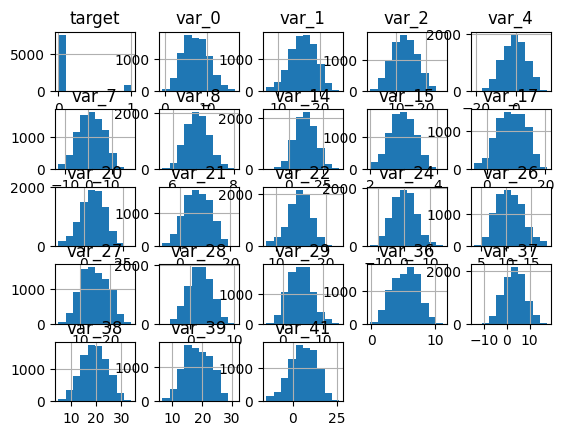

In [36]:
# Display a histogram
df.hist() ;

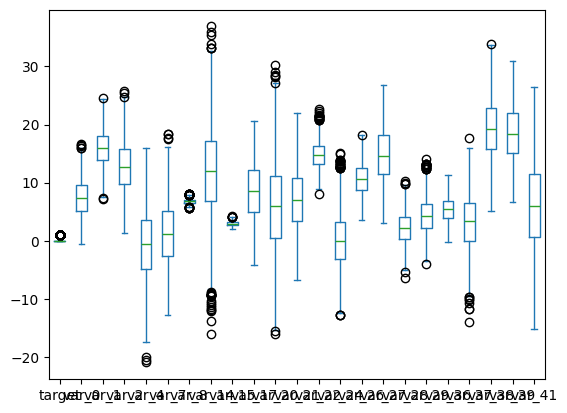

In [37]:
# Display a box and whisker plot
df.plot(kind='box') ;

### Correlation: Independence of Features

In [38]:
# Calculate a correlation matrix
corr_mat = features.corr()

corr_mat

,var_0,var_1,var_2,var_4,var_7,var_8,var_14,var_15,var_17,var_20,...,var_24,var_26,var_27,var_28,var_29,var_36,var_37,var_38,var_39,var_41
var_0,1.000000,-0.001932,-0.002008,-0.004065,0.013920,0.005287,0.009787,0.003501,0.007570,-0.007754,...,0.007211,0.005079,-0.004578,0.001237,-0.010036,-0.008809,-0.000133,0.008856,0.007700,-0.004688
var_1,-0.001932,1.000000,-0.003072,0.019840,-0.010907,-0.010460,-0.013714,-0.001477,-0.002532,-0.008520,...,0.008056,-0.001995,-0.014325,0.003370,-0.010688,0.004288,-0.003056,-0.009136,0.008635,0.022035
var_2,-0.002008,-0.003072,1.000000,0.005686,-0.004277,0.004333,-0.005864,-0.003963,0.001795,-0.013712,...,0.007867,-0.002776,0.015401,0.003564,-0.004052,-0.018087,0.015591,-0.000161,0.011820,0.010744
var_4,-0.004065,0.019840,0.005686,1.000000,-0.002771,-0.011529,0.002493,0.006865,-0.007378,0.010999,...,0.017775,0.005338,0.005084,-0.013891,-0.001566,0.012709,-0.016146,-0.004427,-0.014136,0.001761
var_7,0.013920,-0.010907,-0.004277,-0.002771,1.000000,-0.017535,-0.016141,0.008960,0.007287,-0.031783,...,-0.008173,-0.001197,-0.011280,0.019048,-0.018282,-0.020851,-0.005682,-0.005131,-0.007425,-0.013643
var_8,0.005287,-0.010460,0.004333,-0.011529,-0.017535,1.000000,-0.009329,0.006170,-0.006333,-0.009177,...,-0.003171,-0.011689,-0.001915,-0.005399,0.001543,0.007754,0.013471,-0.000151,0.010374,-0.019808
var_14,0.009787,-0.013714,-0.005864,0.002493,-0.016141,-0.009329,1.000000,-0.002979,-0.002384,-0.016808,...,0.005116,-0.006524,-0.003718,-0.009721,-0.004758,0.021196,0.010578,0.005441,0.003580,-0.002742
var_15,0.003501,-0.001477,-0.003963,0.006865,0.008960,0.006170,-0.002979,1.000000,0.010272,0.004307,...,0.006346,-0.025542,0.015068,0.004778,-0.000226,0.000304,0.013914,0.002860,0.012712,0.020895
var_17,0.007570,-0.002532,0.001795,-0.007378,0.007287,-0.006333,-0.002384,0.010272,1.000000,0.016690,...,0.003891,-0.030515,-0.016135,-0.002544,0.003126,0.013883,-0.004958,0.022471,-0.004214,0.015237
var_20,-0.007754,-0.008520,-0.013712,0.010999,-0.031783,-0.009177,-0.016808,0.004307,0.016690,1.000000,...,-0.001771,0.013170,0.001569,0.003910,0.020686,0.007581,0.020351,-0.000557,0.005733,0.000773


Text(0.5, 23.52222222222222, 'Features')

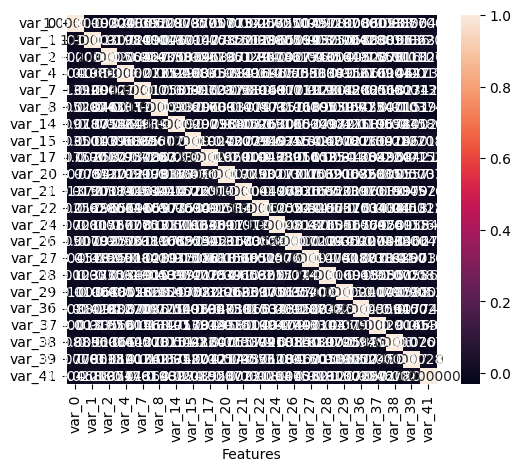

In [39]:
# Heatmap of the correlation matrix
sns.heatmap(
    corr_mat,
    square=True,
    annot=True,
    fmt='2f',
    cbar=True,
)

plt.xlabel('Features')
plt.xlabel('Features')

### Create Two Dataframes (Copies, Not Slices)
1. Successful Transactions
1. Unsuccessful Transactions

In [40]:
# Create a dataframe of successful transactions
successful_df = df[df['target'] == 1].copy()

# Create a dataframe of unsuccessful transactions
unsuccessful_df = df[df['target'] == 0].copy()

## Processing



### Single Cross Validation ( CV )

#### Define an empty Gaussian Naïve Bayes model using Sklearn

In [44]:
# Create an empty GNB model
modelGNB = GaussianNB()

#### Divide the two data sets you created in step 10 into training and testing subsets, i.e. train-test split.

In [45]:
# Train Test Split
X_train, X_test, y_train, y_test = train_test_split(
     features,
     target,
     test_size=0.25
)

In [46]:
# Verify shape of each data set from Train Test Split
for i in [ X_train, X_test, y_train, y_test ]:
  print(i.shape)
  print(type(i))

(6379, 22)
<class 'pandas.core.frame.DataFrame'>
(2127, 22)
<class 'pandas.core.frame.DataFrame'>
(6379,)
<class 'pandas.core.series.Series'>
(2127,)
<class 'pandas.core.series.Series'>


#### Train ( fit ) the model using the training subset of the dataset.

In [47]:
# Train ( fit ) the model
modelGNB.fit( (X_train), y_train)

GaussianNB()

#### Test the model ( predict ) using the testing subset of the dataset.

In [48]:
# Make predicitons using the model
pred_results = modelGNB.predict(X_test)
pred_results * 1000

array([0., 0., 0., ..., 0., 0., 0.])

#### Calculate and report the accuracy.

In [49]:
# Display accuracy
acc = metrics.accuracy_score( y_test,pred_results )
acc * 100

89.37470615890926

#### Present a confusion matrix and heatmap

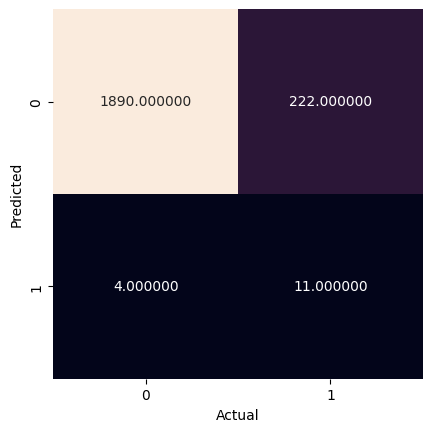

In [50]:
# Display a confusion matrix and heatmap
mat =  metrics.confusion_matrix(
    y_test,
    pred_results
)

sns.heatmap( mat.T,
    square=True,
    annot=True,
    fmt = "2f",
    cbar = False,
)
plt.xlabel('Actual')
plt.ylabel('Predicted');

#### Present the results of a Classification Report (sklearn.metrics.classification_report).

In [51]:
# Display a classification report
print(metrics.classification_report(y_test, pred_results))

              precision    recall  f1-score   support

         0.0       0.89      1.00      0.94      1894
         1.0       0.73      0.05      0.09       233

    accuracy                           0.89      2127
   macro avg       0.81      0.52      0.52      2127
weighted avg       0.88      0.89      0.85      2127



### Conclusion

- In Pass-08, using the big data set, only first 50 columns, and only first 50,000 rows (no balancing):
- Accuracy came out to 89% (same as previous pass)
- Not great at predicting no-transactions
- Good at predicting a successful transaction
- Low false positive (we predict customer will make a transaction but customer does not)
- Medium false negatives (we predict customer will not make a transaction but customer does)

### Future work


- For Pass-09,
  - Use big dataset
  - Use all the rows and columns